# 08 - Make the final Catalogue

From the calibrated frame extract the photometry of the stars using Sextractor<br>
Apply light correction based on the results of the notebook 7.b<br>
Save the final catalogue combining Pycavi and Gaia photometries<br>

Done:<br>
* Sextractor running over the calibrated frame
* Read the catalogue (fits table)
* Read the Gaia catalogue
* Cross match the catalogues
* Create the final catalogue
* Create a merged catalogue of the sextractor images
* Clean the merged sextractor catalogue before comparing with Gaia
* First crossmatch the sextractor catalogues, then cross with Gaia
* Pack the code into the cell
* Add the zero point depending on the filter
* Validate r filter against SkyMapper
* Modify the zp cal notebook to save additional Gaia parameters
* Save the Gaia query as a raw query, create the clean versions as a different files, or add an additional column that defines if the source in each row is used in the clean version.
* Get the zp from the frame itself

ToDo:<br>
* Add the illumination correction for kriggin and chebyshev. Each illumination creates a different catalogue
* order a bit the output catalogue. First three columns must be index, raj2000 and dej2000 from pycavi.
* Modify the papi sextractor function so redo sextractor False efectively do not run sextractor again.
* Validate NB filter against VPHAS

Notes:<br>
* Modified the papi_sextractor to allows the default parameter file to incorporated the position of the stars (XY_IMAGE, ALPHA/DELTA_J2000), as well as the Petro flux and mag.
* Petro mags shows the slopeless results when comparing Sextractor and Gaia mags.
* The zero points for photometry depend on the filter only: 21.40 for r_SDSS and 21.50 for NB in AB system.
* The merged catalogue includes the r_SDSS and NB filters, together with the Gaia data.
* The pycavi ra and dec were mean combined

In [1]:
import os
import sys
import glob
import logging
from datetime import datetime

import pandas as pd
from astropy.io import fits
from astropy.table import Table

sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production
from pycavi import pycavi_tools, pycavi_astromatic_tools
from pycavi.pycavi_zpcal import get_files_dict
from pycavi.pycavi_catalogue import getheaderfromframe, load_catalogue, crossmatch_catalogues, clean_merged_catalogue
from pycavi.pycavi_catalogue import apply_kriggin_illumination_correction, create_catalogue_checkplots

This will be executed when the package is imported.


In [2]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
config = pycavi_tools.read_pycavi_config(config_dir)

observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

log_file_swarp = log_dir + "/pymeffpp_zpcal_check.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['cal_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

observation_tags = list(set(zpcal_dict.keys()))
observation_tags.sort()    # Needed to ensure same index in every run
images_to_check = []
for i in range(len(observation_tags)):
    logging.debug("index: {} observation_tag: {}".format(i, observation_tags[i]))
    for j in range(len(zpcal_dict[observation_tags[i]])):
        images_to_check.append(zpcal_dict[observation_tags[i]][j])

for i in range(len(images_to_check)):
    logging.info("index: {} -- file: {}".format(i, images_to_check[i]))


2024-11-09 13:28:26,312:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_NB_659.coadd.fits
2024-11-09 13:28:26,313:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_r_SDSS.coadd.fits


In [3]:
# The cell above will fail because there is no data in the filter folders, and for some the get_files_dict read files there
# instead, I will do a small modification to just look for files in the swarp folder

images_to_check = glob.glob(reduced_science_dir+'*/Calibration_dir/*.coadd.fits')
images_to_check.sort()

for i in range(len(images_to_check)):
    logging.info("index: {} -- file: {}".format(i, images_to_check[i]))

2024-11-08 14:35:52,028:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_NB_659.coadd.fits
2024-11-08 14:35:52,031:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_r_SDSS.coadd.fits
2024-11-08 14:35:52,031:INFO:index: 2 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_NB_659.coadd.fits
2024-11-08 14:35:52,032:INFO:index: 3 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_r_SDSS.coadd.fits


In [3]:
redo_sextractor = False
idx_selected = [0,1]    # Keep empty to check all files

merged_table = None  # as it creates the sextractor catalogues, starts inmediately to do the crossmatch with the 
                     # previous catalogue

list_of_filters = []
for i in range(len(images_to_check)):
    
    # skip indices not in list idx_selected
    if not (i in idx_selected or not idx_selected):
        continue

    target = images_to_check[i]
    sextractor_dir_path = "/".join(target.split("/")[:-2])+'/'+config['Directories']['sex_dir_name']
    try:
        logging.info("Atempting to create the Sextractor_dir folder: {}".format(reduced_science_dir+target_name))
        os.mkdir(sextractor_dir_path)
        logging.info("Folder created")
    except:
        logging.info("Folder already exists")
    
    # check the filter and object of the target
    target_filter = getheaderfromframe(target, 'FILTER')
    list_of_filters.append(target_filter)
    target_name = getheaderfromframe(target, 'OBJECT').replace(' ', '_')
    
    # run sextractor on frame
    ready_to_sextract = pycavi_astromatic_tools.prepare_to_sextract(target, redo_sextractor)

    # we tune some parameters for sextractr
    special_pars = {}
    special_pars["SATUR_KEY"] = "SATLEVEL"   # FITS keyword giving saturation value
    special_pars["DETECT_MINAREA"] = 5       # minimum number of pixels above threshold
    special_pars["DETECT_MAXAREA"] = 0       # maximun number of pixels above threshold
    special_pars["DETECT_THRESH"] = 5.0      # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
    special_pars["ANALYSIS_THRESH"] = 5.0    # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
    special_pars["SEEING_FWHM"] = 1.2        # stellar FWHM in arcsec (we give here typical not so good value)
    special_pars["PHOT_APERTURES"] = 5       # MAG_APER aperture diameter(s) in pixels
    special_pars["MAG_ZEROPOINT"] = getheaderfromframe(target, 'MAGZP')    # magnitude zero-point from the frames header
    special_pars["GAIN"] =  1.0              # detector gain in e-/ADU - if DN in e/s then 1.0
    special_pars["MEMORY_OBJSTACK"] = 6000   # number of objects in stack [3000]
    special_pars["MEMORY_PIXSTACK"] = 600000 # number of pixels in stack [300000]

    # the measurement parameters to get during the extraction. They will be present in the final catalogue
    # the mandatory parameter list is required to do the cross match between catalogues
    # the optionally parameter list includes all the rest of desired parameters to be extracted
    mandatory_parameter_list = ['NUMBER', 'ALPHA_J2000', 'DELTA_J2000']
    optionally_parameter_list = ['MAG_ISO', 'MAGERR_ISO', 'MAG_PETRO', 'MAGERR_PETRO', 'MAG_AUTO', 'MAGERR_AUTO', 'MAG_BEST', 'MAGERR_BEST', 
                                 'X_IMAGE', 'Y_IMAGE', 'A_IMAGE', 'B_IMAGE', 'THETA_IMAGE', 'FLAGS']
    parameter_list = mandatory_parameter_list + optionally_parameter_list
    special_pars['PARAMETERS_LIST'] = parameter_list
    
    if ready_to_sextract:
        if not os.path.isfile(target[:-5]+'.cat') or redo_sextractor:
            pycavi_astromatic_tools.run_sextractor_on_target(images_to_check[i], sextractor_dir_path, special_pars)
    
    # sextractor is done
    logging.info("SExtractor finished on image {}".format(target.split("/")[-1]))
    
    # start the cross matching process
    # add the filter tag to each column in the table to differentiate from the other data
    if merged_table is None:
        logging.info('Creating catalogue for filter '+target_filter)
        merged_table = load_catalogue(target[:-5]+'.cat')
        # add the filter tag to each column in the catalogue to make them unique
        for col in merged_table.colnames:
            merged_table.rename_column(col, col+'_'+target_filter)
        # save the filter tag that will identify the merged catalogue from here on
        merged_filter = target_filter
    else:
        single_table = load_catalogue(target[:-5]+'.cat')
        # update the column names by adding the filter tag
        for col in single_table.colnames:
            single_table.rename_column(col, col+'_'+target_filter)
        # defines the ra and dec tags for the single catalogue
        radec_tag_single = ['ALPHA_J2000_'+target_filter, 'DELTA_J2000_'+target_filter]
        radec_tag_merged = ['ALPHA_J2000_'+merged_filter, 'DELTA_J2000_'+merged_filter]
        logging.info('Crossmatching {} and {} catalogues...'.format(merged_filter, target_filter))
        merged_table = crossmatch_catalogues(merged_table, single_table, 
                                             radec_tag_1=radec_tag_merged, radec_tag_2=radec_tag_single)

# Clean merged table

savename = '/'.join(target.split('/')[:-1]) +'/'+ target_name + '_merged_catalogue.fits'
clean_table = clean_merged_catalogue(merged_table)

# cross match with Gaia and save
logging.info('Reading Gaia query...')
target_split = target.split('/')
query_gaia = '/'.join(target.split('/')[:-1])+'/gaia3_qry_{}_raw.csv'.format(target_name)
gaia_catalogue = pd.read_csv(query_gaia)
gaia_catalogue = Table.from_pandas(gaia_catalogue)

for col in gaia_catalogue.colnames:
    gaia_catalogue.rename_column(col, col+'_gaia')

logging.info('Crossmatching Pycavi and Gaia catalogues...')
merged_clean_gaia = crossmatch_catalogues(clean_table, gaia_catalogue, 
                                          radec_tag_1=['raj2000', 'dej2000'], 
                                          radec_tag_2=['raj2000_gaia', 'dej2000_gaia'])

# Convert the Astropy Table to a Table HDU
table_hdu = fits.BinTableHDU(merged_clean_gaia)

logging.info('Adding basic headers to the catalogue...')
# Create a Primary HDU with custom headers
now = datetime.now()
formatted_date = now.strftime("%Y-%m-%dT%H:%S.%f")[:-3] # ISO 8601 truncated to millisecond

primary_hdu = fits.PrimaryHDU()
primary_hdu.header['DATE'] = (formatted_date, 'Date of creation of this catalogue')
primary_hdu.header['ORIGFILE'] = "SPDP."+formatted_date+".fits"
primary_hdu.header['TELESCOP'] = ('ESO-VST', 'ESO Telescope Designation')
primary_hdu.header['INSTRUME'] = ('OMEGACAM', 'Instrument name')
for i in range(len(list_of_filters)):
    primary_hdu.header['FILTER{:02d}'.format(i)] = (list_of_filters[i], 'Name of filter used for catalogue') 
primary_hdu.header['OBJECT'] = (target_name.replace('_',' '), 'Name of the pointing target')
primary_hdu.header['RA'] = (getheaderfromframe(target, 'RA'), 'Tile center RA J2000')
primary_hdu.header['DEC'] = (getheaderfromframe(target, 'DEC'), 'Tile center Dec J2000')

# Combine Primary HDU and Table HDU into an HDUList
hdul = fits.HDUList([primary_hdu, table_hdu])

# Write to a FITS file
logging.info('Saving merged catalogue as '+savename)
hdul.writeto(savename, overwrite=True)

logging.info("-------Done-------")

2024-11-09 13:29:08,167:INFO:Folder already exists
2024-11-09 13:29:08,172:INFO:Running Sextractor on image BD_Pav_NB_659.coadd.fits
2024-11-09 13:29:08,174:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir
2024-11-09 13:29:08,175:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-11-09 13:29:08,176:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-11-09 13:29:08,176:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-11-09 13:29:08,176:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-11-09 13:29:08,177:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-11-09 13:29:08,177:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-11-09 13:29:08,177:INFO:sextractor.config[PHOT_APERTURES] = 5
2024-11-09 13:29:08,177:INFO:sextractor.config[MAG_ZEROPOINT] = -21.476
2024-11-09 13:29:08,178:INFO:sextractor.config[GAIN] = 1.0
2024-11-09 13:29:08,178:INFO:sextractor.config[MEMORY_OBJSTACK] = 6000
2024-11-09 13:29:08,178:INFO:sextractor.config[MEMORY

sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir


2024-11-09 13:29:21,868:INFO:SExtractor finished on image BD_Pav_NB_659.coadd.fits
2024-11-09 13:29:21,868:INFO:Creating catalogue for filter NB_659
2024-11-09 13:29:21,880:INFO:Atempting to create the Sextractor_dir folder: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav
2024-11-09 13:29:21,881:INFO:Folder already exists
2024-11-09 13:29:21,885:INFO:Running Sextractor on image BD_Pav_r_SDSS.coadd.fits
2024-11-09 13:29:21,887:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir
2024-11-09 13:29:21,888:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-11-09 13:29:21,888:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-11-09 13:29:21,889:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-11-09 13:29:21,889:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-11-09 13:29:21,889:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-11-09 13:29:21,890:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-11-09 13:29:21,890:INFO:sextr

py-sextractor.cat --> BD_Pav_NB_659.coadd.cat
sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir


2024-11-09 13:29:37,044:INFO:SExtractor finished on image BD_Pav_r_SDSS.coadd.fits
2024-11-09 13:29:37,055:INFO:Crossmatching NB_659 and r_SDSS catalogues...
2024-11-09 13:29:37,143:INFO:Reading Gaia query...
2024-11-09 13:29:37,182:INFO:Crossmatching Pycavi and Gaia catalogues...


py-sextractor.cat --> BD_Pav_r_SDSS.coadd.cat


2024-11-09 13:29:37,384:INFO:Adding basic headers to the catalogue...
2024-11-09 13:29:37,388:INFO:Saving merged catalogue as /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_merged_catalogue.fits
2024-11-09 13:29:37,481:INFO:-------Done-------


## Illumination correction

The illumination correction is applied to the merged catalogue. For the moment it only consider the kriggin files.

In [4]:
catalogues = glob.glob(reduced_science_dir+'*/Calibration_dir/*merged_catalogue.fits')
kriging_files = glob.glob(reduced_science_dir+'*/Calibration_dir/*.kriging.fits')
kriging_files.sort()

logging.info('Available catalogues:')
for i in range(len(catalogues)):
    logging.info("index: {} -- file: {}".format(i, catalogues[i]))

logging.info('Available Kriging illumination correction files:')
for i in range(len(kriging_files)):
    logging.info("index: {} -- file: {}".format(i, kriging_files[i]))

2024-11-09 13:33:26,752:INFO:Available catalogues:
2024-11-09 13:33:26,753:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_merged_catalogue.fits
2024-11-09 13:33:26,754:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_merged_catalogue.fits
2024-11-09 13:33:26,755:INFO:index: 2 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_merged_catalogue.fits
2024-11-09 13:33:26,755:INFO:Available Kriging illumination correction files:
2024-11-09 13:33:26,756:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_NB_659.coadd_krige_gaussian_nugget_fit_01.kriging.fits
2024-11-09 13:33:26,757:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_r_SDSS.coadd_krige_gaussian_nugget_fit_01.kriging.fits
2024-11-09 13:33:26,758:INFO:i

In [6]:
# specify the catalogues to use
catalogue_idx = [1]
kriging_idx = [0,1]

for i in range(len(catalogues)):
    if not i in catalogue_idx:
        continue
    logging.info('Applying illumination correction to catalogue {}'.format(catalogues[i]))
    for j in range(len(kriging_files)):
        if not j in kriging_idx:
            continue
        logging.info('Applying Kriging illumination correction file: {}'.format(kriging_files[j]))

        corr = apply_kriggin_illumination_correction(kriging_files[j], catalogues[i])
        

2024-11-09 13:34:07,742:INFO:Applying illumination correction to catalogue /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_merged_catalogue.fits
2024-11-09 13:34:07,744:INFO:Applying Kriging illumination correction file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_NB_659.coadd_krige_gaussian_nugget_fit_01.kriging.fits
2024-11-09 13:34:08,000:INFO:Applying Kriging illumination correction file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_r_SDSS.coadd_krige_gaussian_nugget_fit_01.kriging.fits


## Check plots

After the illumination correction was applied, we can create some check plots to see how good or bad the calibration was

In [7]:
catalogues = glob.glob(reduced_science_dir+'*/Calibration_dir/*merged_catalogue.fits')

logging.info('Available catalogues:')
for i in range(len(catalogues)):
    logging.info("index: {} -- file: {}".format(i, catalogues[i]))

2024-11-09 13:34:10,695:INFO:Available catalogues:
2024-11-09 13:34:10,696:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_merged_catalogue.fits
2024-11-09 13:34:10,697:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_merged_catalogue.fits
2024-11-09 13:34:10,698:INFO:index: 2 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_merged_catalogue.fits


2024-11-09 13:34:40,880:INFO:Creating check plots over catalogue /home/lceledon/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav_merged_catalogue.fits
/home/lceledon/Software/miniconda3/envs/workenv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/lceledon/Software/miniconda3/envs/workenv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


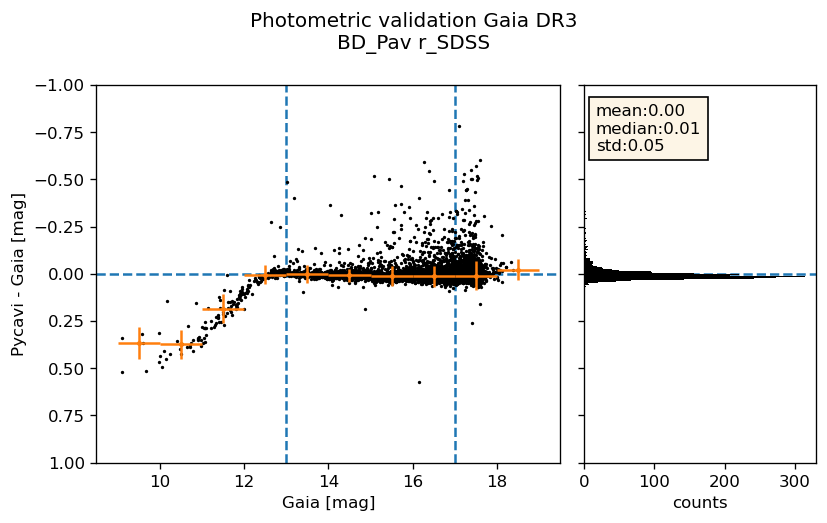

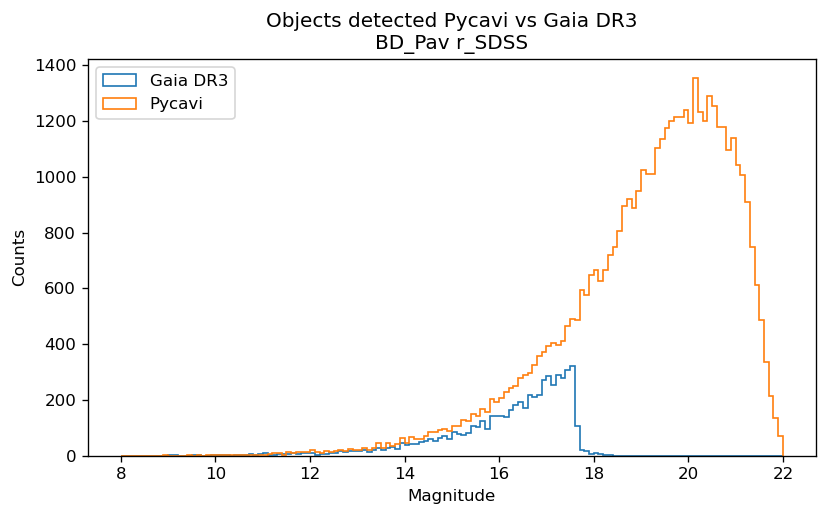

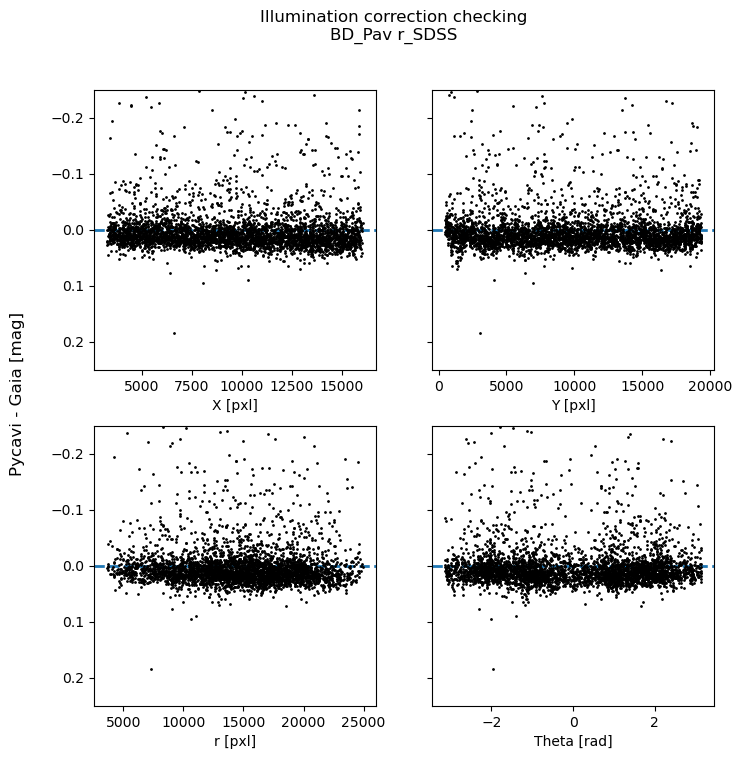

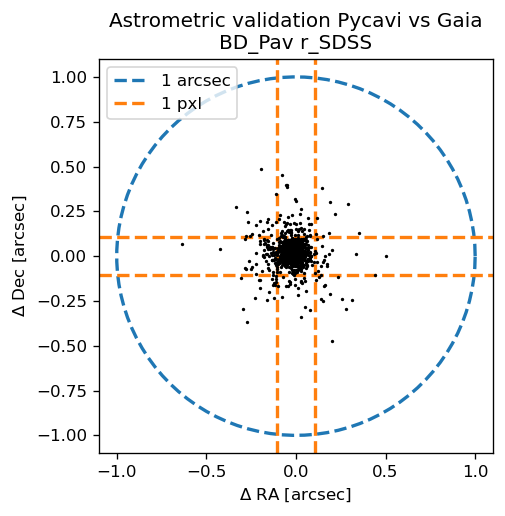

In [9]:
band = 'r_SDSS'
catalogue_idx = [1]
for i in range(len(catalogues)):
    if not i in catalogue_idx:
        continue
    logging.info('Creating check plots over catalogue {}'.format(catalogues[i]))
    create_catalogue_checkplots(catalogues[i], band)